Quantum Computing Midterm Project

Step 1

In [84]:
import numpy as np 
import matplotlib.pyplot as plt

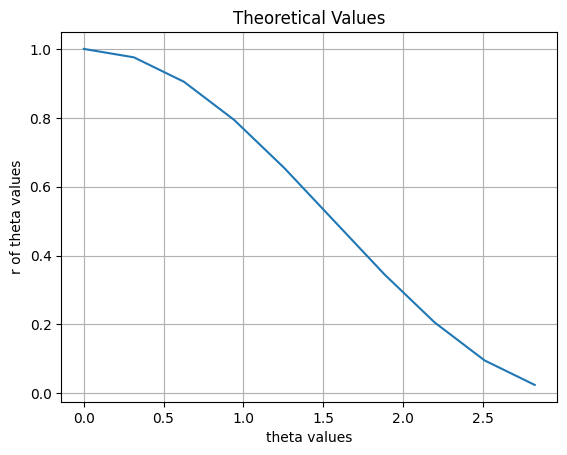

In [85]:
theta=np.arange(0, np.pi, 0.1*np.pi)
r_theta=np.cos(theta/2)**2
plt.plot(theta, r_theta)
plt.grid(True)
plt.xlabel("theta values")
plt.ylabel("r of theta values")
plt.title('Theoretical Values')
plt.show()

Step 2

In [86]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

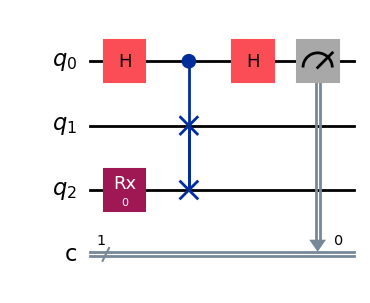

In [87]:
##Make Swap Test Circuit
qc=QuantumCircuit(3,1) #three quibits, one classical bit to register measurement
qc.h(0)
qc.rx(0, 2, 'Rx')  #dummy angle
qc.cswap(0,1,2)  #swap: control is 0, targets (1, 2)
qc.h(0)  #hadmard again
qc.measure(0,0) #measures 0th qubit and puts it on the 0th classical bit
qc.draw('mpl')


In [88]:
simulator = AerSimulator()
probabilities=[]
r_values=[]
shots=1000
for angle in theta:
    qc=QuantumCircuit(3,1)    #reconstruct Circuit with varying theta
    qc.h(0)
    qc.rx(angle, 2) #add the rx from the equation
    qc.cswap(0,1,2)
    qc.h(0)
    qc.measure(0,0)
    
    job = simulator.run(qc, shots=shots)   #run on sim
    result = job.result()


    counts = result.get_counts()
    print(counts)
    zero_counts = counts.get('0', 0)
    
    prob_zero = zero_counts / shots #calcute probability of 0
    r = (2 * prob_zero) - 1       #calculate r
    
    # 6. Store the results in your lists
    probabilities.append(prob_zero)
    r_values.append(r)

{'0': 1000}
{'0': 989, '1': 11}
{'0': 958, '1': 42}
{'0': 902, '1': 98}
{'0': 841, '1': 159}
{'0': 765, '1': 235}
{'1': 328, '0': 672}
{'0': 600, '1': 400}
{'0': 534, '1': 466}
{'0': 517, '1': 483}


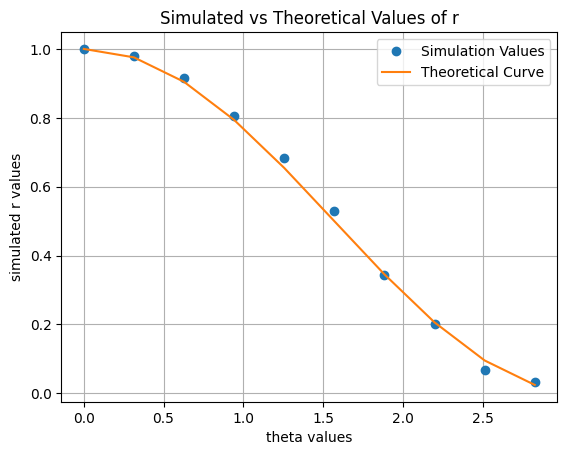

In [89]:
plt.plot(theta, r_values, 'o', label="Simulation Values")
plt.plot(theta, r_theta, label='Theoretical Curve')
plt.grid(True)
plt.xlabel("theta values")
plt.ylabel("simulated r values")
plt.title('Simulated vs Theoretical Values of r')
plt.legend()
plt.show()

Extra Credit

In [90]:
from qiskit import transpile
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_ibm_runtime import SamplerV2 as Sampler

service = QiskitRuntimeService(channel='ibm_cloud')
backend = service.least_busy(operational=True, simulator=False)
status = backend.status()
print(f"Running on backend: {backend.name} (pending jobs: {status.pending_jobs})")

all_circuits = []
shots = 100

for angle in theta:
    qc = QuantumCircuit(3, 1)
    qc.h(0)
    qc.rx(angle, 2)
    qc.cswap(0, 1, 2)
    qc.h(0)
    qc.measure(0, 0)
    all_circuits.append(qc)

print("Transpiling circuits...")
transpiled_circuits = transpile(all_circuits, backend=backend, optimization_level=1)

sampler = Sampler(mode=backend)
pubs = [(qc, None, shots) for qc in transpiled_circuits]

print("Submitting job...")
job = sampler.run(pubs)
job_id = job.job_id()
print(f"Job ID: {job_id}")
print(f"Initial status: {job.status()}")
print("Waiting for results...")

job_result = job.result()

real_probabilities = []
real_r_values = []

for i, pub_result in enumerate(job_result):
    counts = pub_result.data.c.get_counts()
    zero_counts = counts.get('0', 0)
    total_counts = sum(counts.values())
    prob_zero = zero_counts / total_counts
    r = (2 * prob_zero) - 1
    real_probabilities.append(prob_zero)
    real_r_values.append(r)

print("Hardware results ready to plot!")

Running on backend: ibm_marrakesh (pending jobs: 1)
Transpiling circuits...
Submitting job...
Job ID: dbj93l1ffo6c73b9639g
Initial status: QUEUED
Waiting for results...
Hardware results ready to plot!


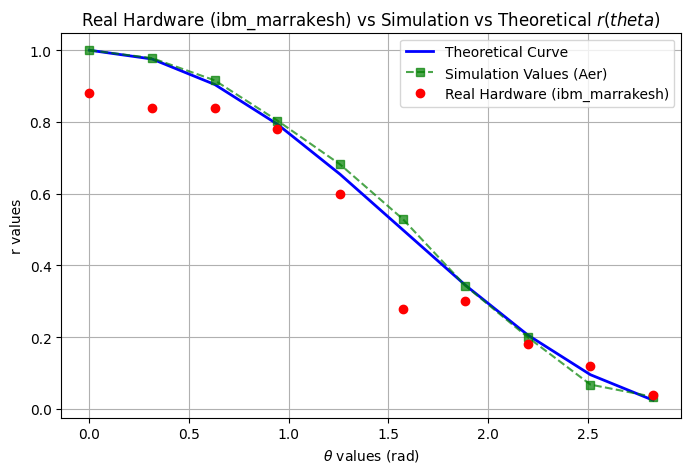

In [92]:
plt.figure(figsize=(8, 5))
plt.plot(theta, r_theta, label='Theoretical Curve', color='blue', linewidth=2)
plt.plot(theta, r_values, 's--', label='Simulation Values (Aer)', color='green', alpha=0.7)
plt.plot(theta, real_r_values, 'o', label=f'Real Hardware ({backend.name})', color='red', markersize=6)
plt.grid(True)
plt.xlabel(r"$\theta$ values (rad)")
plt.ylabel("r values")
plt.title(f'Real Hardware ({backend.name}) vs Simulation vs Theoretical $r(\ttheta)$')
plt.legend()
plt.show()